<a href="https://colab.research.google.com/github/shashikant-ds636/easycluster/blob/main/examples/clustereasy_quickstart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# clustereasy — Quickstart

Run this notebook directly in Google Colab, Jupyter, or VS Code. It installs `clustereasy`, builds a synthetic customer dataset, and walks through K-Means and Agglomerative Clustering end to end.

In [1]:
# Works the same in Colab, Jupyter, and plain scripts.
# In Colab/Jupyter, the leading ! runs it as a shell command.
!pip install -q clustereasy

In [2]:
import numpy as np
import pandas as pd
from clustereasy import Cluster

np.random.seed(42)
n = 200
df = pd.DataFrame({
    "CustomerID": range(1, n + 1),
    "Annual Income": np.concatenate([np.random.normal(25, 5, n // 2), np.random.normal(75, 8, n - n // 2)]),
    "Spending Score": np.concatenate([np.random.normal(30, 10, n // 2), np.random.normal(70, 10, n - n // 2)]),
})
df.head()

,CustomerID,Annual Income,Spending Score
0,1,27.483571,33.577874
1,2,24.308678,35.607845
2,3,28.238443,40.830512
3,4,32.615149,40.538021
4,5,23.829233,16.223306


## 1. K-Means

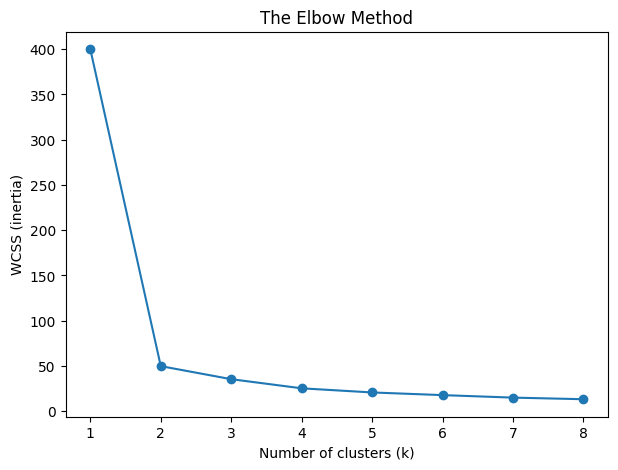

,n_clusters,wcss
0,1,400.000000
1,2,49.796206
2,3,35.374940
3,4,25.275239
4,5,20.705124
5,6,17.760603
6,7,14.998356
7,8,13.227998


In [3]:
cluster = Cluster(data=df, features=["Annual Income", "Spending Score"], scale=True)

# Elbow method to help choose k
cluster.elbow_method(max_clusters=8)


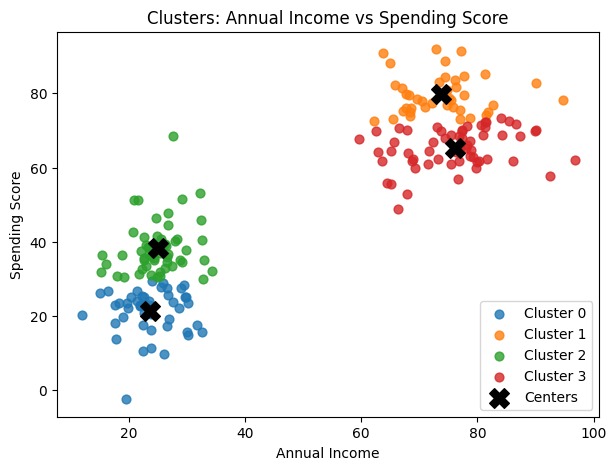

<Axes: title={'center': 'Clusters: Annual Income vs Spending Score'}, xlabel='Annual Income', ylabel='Spending Score'>

In [4]:
cluster.fit_kmeans(n_clusters=4, random_state=42)
cluster.plot_clusters(x="Annual Income", y="Spending Score")


In [5]:
cluster.evaluate()

,metric,value,note
0,silhouette_score,0.426777,None
1,davies_bouldin_score,0.855516,None
2,calinski_harabasz_score,968.616652,None
3,inertia,25.275239,None


In [6]:
labeled_df = cluster.get_clustered_data(column_name="Segment")
labeled_df.head()

,CustomerID,Annual Income,Spending Score,Segment
0,1,27.483571,33.577874,2
1,2,24.308678,35.607845,2
2,3,28.238443,40.830512,2
3,4,32.615149,40.538021,2
4,5,23.829233,16.223306,0


## 2. Agglomerative (Hierarchical) Clustering

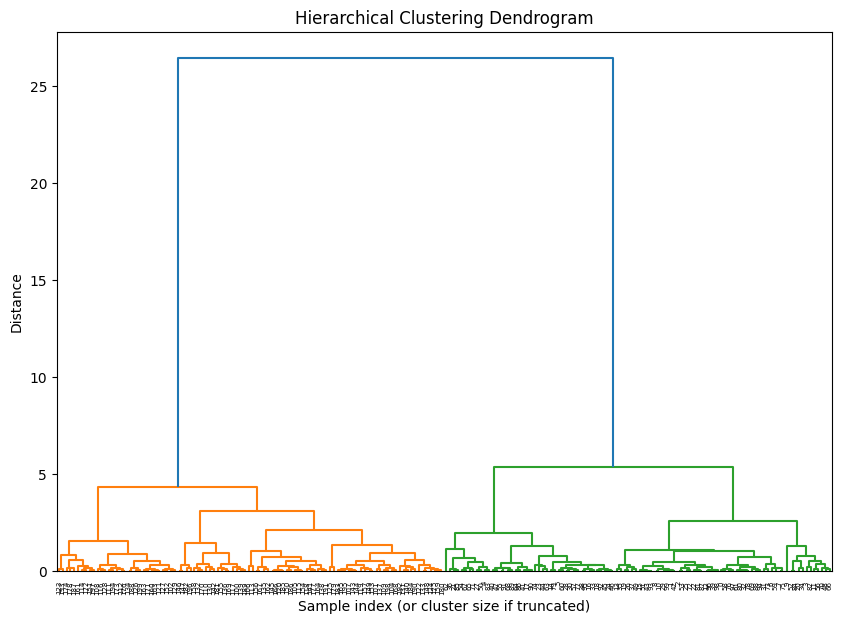

array([[2.80000000e+01, 3.00000000e+01, 6.70391486e-03, 2.00000000e+00],
       [5.50000000e+01, 9.10000000e+01, 8.14978743e-03, 2.00000000e+00],
       [4.30000000e+01, 9.30000000e+01, 8.80380643e-03, 2.00000000e+00],
       [1.59000000e+02, 1.80000000e+02, 1.09750697e-02, 2.00000000e+00],
       [1.45000000e+02, 1.66000000e+02, 1.28279891e-02, 2.00000000e+00],
       [2.40000000e+01, 4.60000000e+01, 1.60944450e-02, 2.00000000e+00],
       [1.56000000e+02, 1.67000000e+02, 1.67874505e-02, 2.00000000e+00],
       [1.15000000e+02, 1.54000000e+02, 1.79914733e-02, 2.00000000e+00],
       [3.20000000e+01, 7.80000000e+01, 2.28596692e-02, 2.00000000e+00],
       [2.00000000e+00, 5.30000000e+01, 2.35365606e-02, 2.00000000e+00],
       [1.33000000e+02, 1.48000000e+02, 2.35958340e-02, 2.00000000e+00],
       [2.90000000e+01, 9.90000000e+01, 2.47737557e-02, 2.00000000e+00],
       [1.34000000e+02, 1.88000000e+02, 2.48199394e-02, 2.00000000e+00],
       [8.00000000e+00, 1.00000000e+01, 2.48689446e

In [7]:
cluster.plot_dendrogram(method="ward")


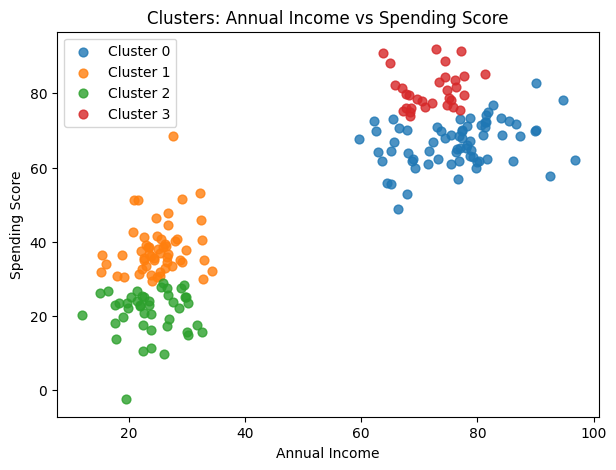

<Axes: title={'center': 'Clusters: Annual Income vs Spending Score'}, xlabel='Annual Income', ylabel='Spending Score'>

In [8]:
cluster.fit_agglomerative(n_clusters=4, linkage="ward")
cluster.plot_clusters(x="Annual Income", y="Spending Score", show_centers=False)


In [9]:
cluster.evaluate()  # no inertia for Agglomerative — not a native attribute

,metric,value,note
0,silhouette_score,0.422632,None
1,davies_bouldin_score,0.831339,None
2,calinski_harabasz_score,937.507764,None


In [10]:
labeled_df = cluster.get_clustered_data(column_name="Segment")
labeled_df.head()

,CustomerID,Annual Income,Spending Score,Segment
0,1,27.483571,33.577874,1
1,2,24.308678,35.607845,1
2,3,28.238443,40.830512,1
3,4,32.615149,40.538021,1
4,5,23.829233,16.223306,2
